In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn import preprocessing
%matplotlib inline

In [36]:
df = pd.read_csv('teleCust1000t.csv')
df.head()

,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
0,2,13,44,1,9,64.0,4,5,0.0,0,2,1
1,3,11,33,1,7,136.0,5,5,0.0,0,6,4
2,3,68,52,1,24,116.0,1,29,0.0,1,2,3
3,2,33,33,0,12,33.0,2,0,0.0,1,1,1
4,2,23,30,1,9,30.0,1,2,0.0,0,4,3


In [13]:
df.describe()
# classification to he best 


,region,tenure,age,marital,address,income,ed,employ,retire,gender,reside,custcat
count,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2.0220,35.526000,41.684000,0.495000,11.551000,77.535000,2.671000,10.987000,0.047000,0.517000,2.331000,2.487000
std,0.8162,21.359812,12.558816,0.500225,10.086681,107.044165,1.222397,10.082087,0.211745,0.499961,1.435793,1.120306
min,1.0000,1.000000,18.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,1.0000,17.000000,32.000000,0.000000,3.000000,29.000000,2.000000,3.000000,0.000000,0.000000,1.000000,1.000000
50%,2.0000,34.000000,40.000000,0.000000,9.000000,47.000000,3.000000,8.000000,0.000000,1.000000,2.000000,3.000000
75%,3.0000,54.000000,51.000000,1.000000,18.000000,83.000000,4.000000,17.000000,0.000000,1.000000,3.000000,3.000000
max,3.0000,72.000000,77.000000,1.000000,55.000000,1668.000000,5.000000,47.000000,1.000000,1.000000,8.000000,4.000000


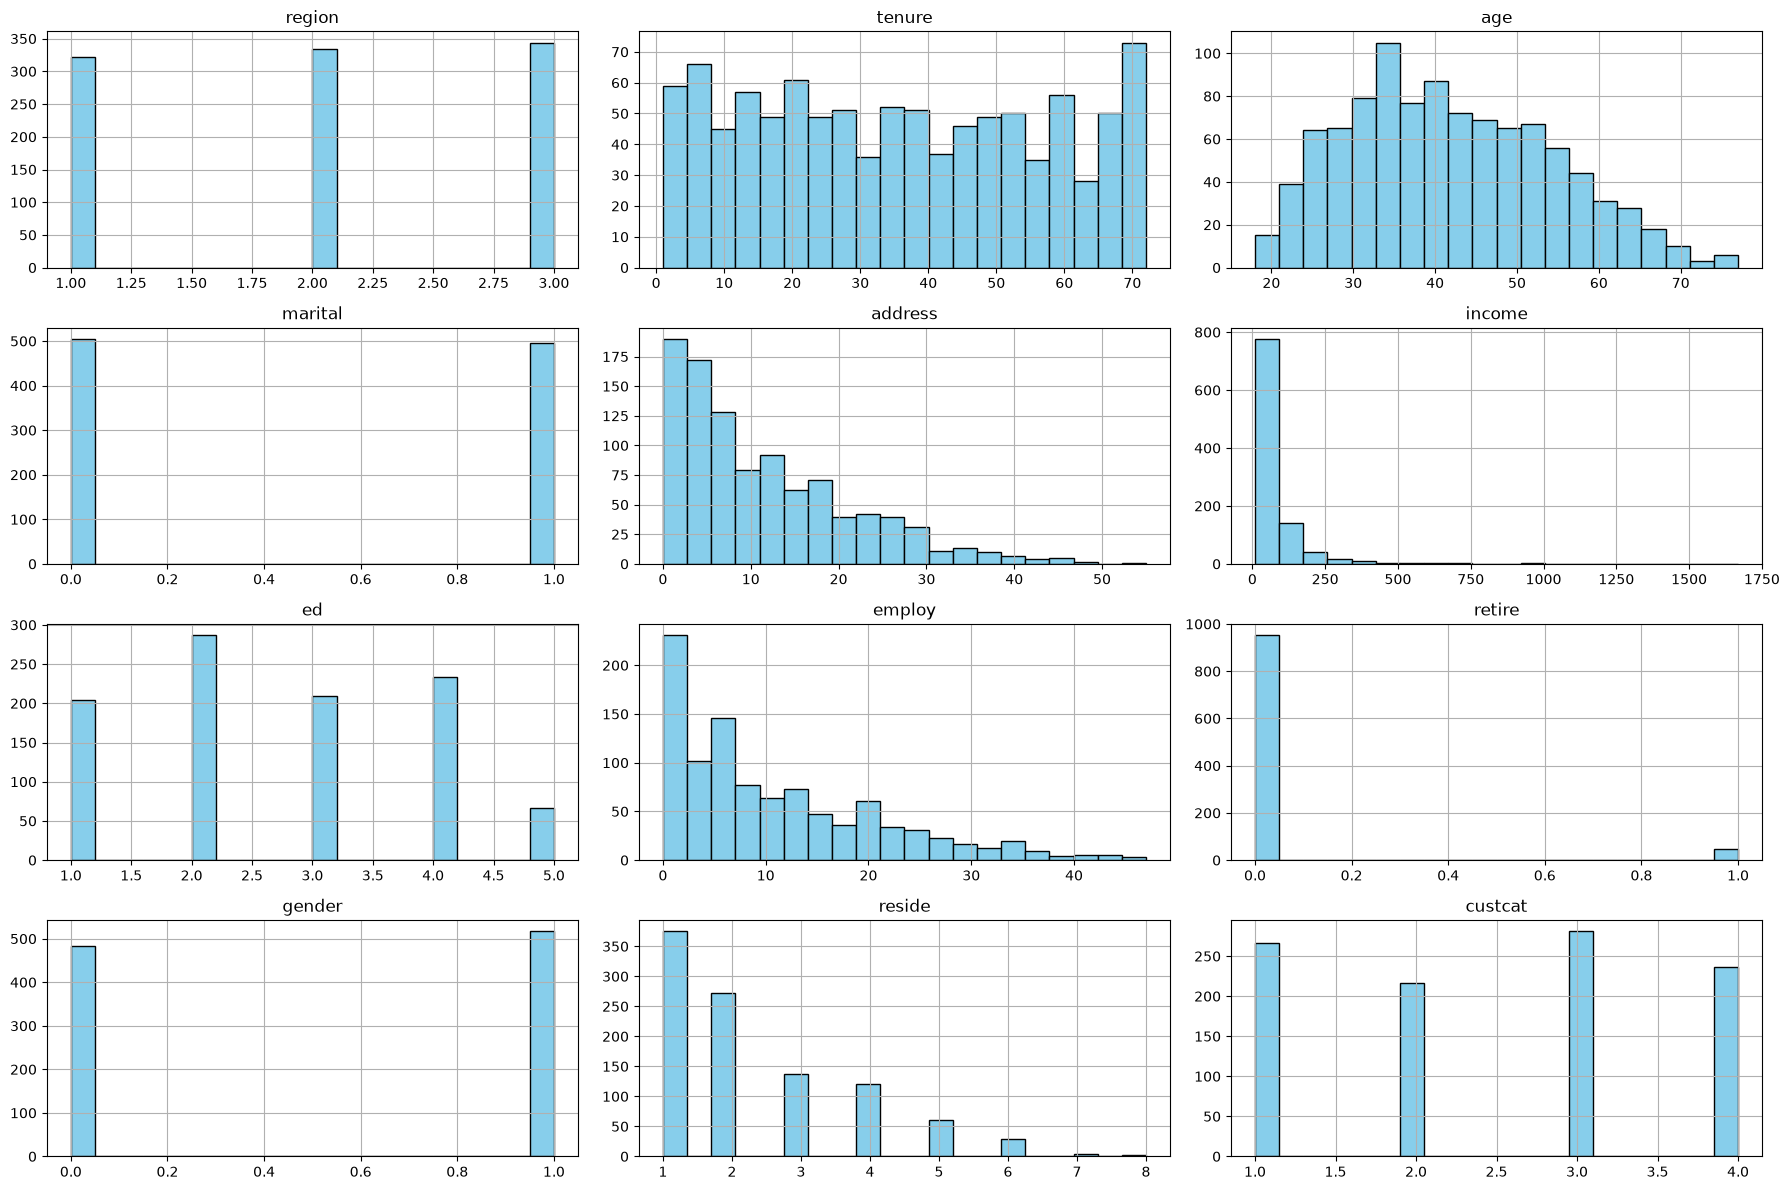

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

df.hist(
    figsize=(18, 12),
    bins=20,
    edgecolor='black',
    color='skyblue'
)

plt.tight_layout()
plt.show()

In [21]:
for col in df.columns:
    print(f"col{col}",df[col].value_counts(dropna=False))

colregion region
3    344
2    334
1    322
Name: count, dtype: int64
coltenure tenure
72    31
3     20
48    20
24    20
13    19
      ..
47     7
36     7
2      7
21     6
63     6
Name: count, Length: 72, dtype: int64
colage age
33    39
39    35
35    34
34    32
31    32
37    31
40    28
42    28
30    26
52    25
36    25
41    24
54    24
46    24
48    24
43    24
27    24
45    24
50    23
51    23
25    23
28    22
38    21
26    21
55    21
47    21
32    21
44    20
57    20
24    20
29    19
53    19
49    18
23    16
22    15
59    14
63    12
60    11
61    11
56    11
20    10
58    10
64    10
62     9
21     8
66     7
68     6
69     6
65     6
67     5
19     4
76     3
70     3
75     2
71     1
72     1
74     1
77     1
18     1
73     1
Name: count, dtype: int64
colmarital marital
0    505
1    495
Name: count, dtype: int64
coladdress address
1     68
2     66
3     61
4     61
0     56
7     53
5     50
9     41
8     39
10    38
12    36
6     36
13    33


In [24]:
# create that classification with KNN 

In [26]:
X = df[['region', 'tenure','age', 'marital', 'address', 'income', 'ed', 'employ','retire', 'gender', 'reside']] .values  #.astype(float)


In [28]:
cols = ['region','tenure','age','marital','address','income','ed',
        'employ','retire','gender','reside']
idx = {c: i for i, c in enumerate(cols)}

# دو ستون از X
arr1 = X[:, idx['age']].astype(float)
arr2 = X[:, idx['income']].astype(float)

result = plot_two_arrays(
    arr1, arr2,
    labels=('age', 'income'),
    colors=('tab:blue', 'tab:orange'),
    mode='line',
    title='age vs income با نمایش تقاطع‌ها'
)

print("ایندکس تقاطع‌ها:", result['intersection_indices'])

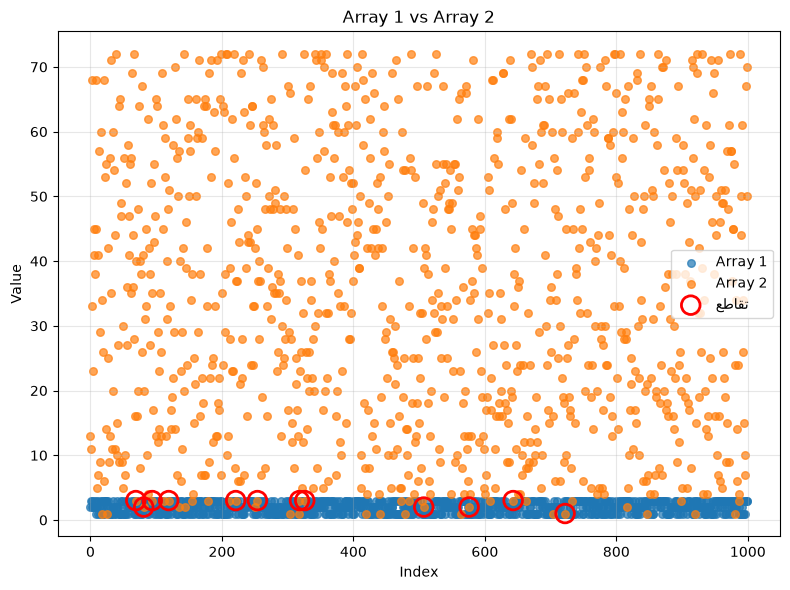

{'intersection_indices': array([ 69,  81,  94, 119, 221, 254, 318, 326, 507, 576, 643, 722]),
 'intersection_values': array([3., 2., 3., 3., 3., 3., 3., 3., 2., 2., 3., 1.])}

In [37]:
plot_two_arrays(
    df['region'],
    df['tenure'],
)

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

def check_separability(X, y, idx_map, f1, f2,
                       figsize=(7, 5),
                       title=None,
                       show_auc=True):
    """
    رسم دو ویژگی در برابر هم، رنگ‌بندی بر اساس کلاس y.
    اگر دو کلاس جدا افتادن، یعنی این دو ویژگی برای طبقه‌بندی مفیدن.

    Parameters
    ----------
    X : np.ndarray
        ماتریس ویژگی‌ها.
    y : array-like
        برچسب کلاس (0/1 یا هر دسته).
    idx_map : dict
        نگاشت نام ستون به ایندکس (چون X تبدیل به آرایه شده).
    f1, f2 : str
        دو ویژگی برای محور X و Y.
    show_auc : bool
        آیا AUC هر ویژگی به‌تنهایی هم چاپ بشه؟

    Returns
    -------
    dict با AUC هر ویژگی و AUC مدل ساده روی ترکیب دو ویژگی.
    """
    x1 = X[:, idx_map[f1]].astype(float)
    x2 = X[:, idx_map[f2]].astype(float)
    y_arr = np.asarray(y)

    classes = np.unique(y_arr)

    fig, ax = plt.subplots(figsize=figsize)
    colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

    for c, col in zip(classes, colors):
        m = y_arr == c
        ax.scatter(x1[m], x2[m], s=35, alpha=0.75,
                   color=col, label=f'class = {c}  (n={m.sum()})',
                   edgecolor='k', linewidth=0.3)

    ax.set_xlabel(f1)
    ax.set_ylabel(f2)
    ax.set_title(title or f'جدایی‌پذیری کلاس‌ها با «{f1}» و «{f2}»')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # --- ارزیابی کمّی ---
    result = {}
    if show_auc and len(classes) == 2:
        # AUC هر ویژگی به تنهایی (با قدر مطلق)
        auc1 = roc_auc_score(y_arr, x1)
        auc2 = roc_auc_score(y_arr, x2)
        result['auc_' + f1] = max(auc1, 1 - auc1)
        result['auc_' + f2] = max(auc2, 1 - auc2)

        # AUC با مدل خطی ساده روی دو ویژگی (مشخص می‌کنه ترکیب دو ویژگی چقدر خوبه)
        try:
            from sklearn.linear_model import LogisticRegression
            from sklearn.model_selection import cross_val_score
            lr = LogisticRegression(max_iter=1000)
            scores = cross_val_score(lr, np.c_[x1, x2], y_arr,
                                     cv=5, scoring='roc_auc')
            result['auc_combo_cv'] = scores.mean()
        except Exception as e:
            result['auc_combo_cv'] = None

        print(f"AUC({f1}) alone       = {result['auc_'+f1]:.3f}")
        print(f"AUC({f2}) alone       = {result['auc_'+f2]:.3f}")
        if result['auc_combo_cv'] is not None:
            print(f"AUC({f1} + {f2}) CV  = {result['auc_combo_cv']:.3f}")

    return result

In [35]:
check_separability(
    df['region'],
    df['income'],
)

TypeError: check_separability() missing 3 required positional arguments: 'idx_map', 'f1', and 'f2'